

**读取 ERP → 为每个立方体面生成三维方向 → 方向转经纬度 → ERP 采样坐标 → 双线性插值 → 显示和保存六面。**


In [1]:
import torch
import numpy as np
import math
from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import display
import torch.nn.functional as F

FACE_NAMES = ('+X', '-X', '+Y', '-Y', '+Z', '-Z')
print('PyTorch:', torch.__version__)

PyTorch: 2.11.0+cu128


In [2]:
def make_face_directions(face_size, face, device=None, dtype=torch.float32):
    """Return unit directions [S, S, 3]; image rows point down, world +Y up."""
    if not isinstance(face_size, int) or face_size < 1:
        raise ValueError('face_size must be a positive integer')
    if face not in FACE_NAMES:
        raise ValueError(f'Unknown face: {face}')

    # Sample pixel centers, not the outer boundaries of the square.
    axis = (torch.arange(face_size, device=device, dtype=dtype) + 0.5)
    # -> [0, 1] -> [0, 2] - [-1, 1]
    axis = 2 * axis / face_size - 1
    # t face_size * face_size
    t, s = torch.meshgrid(axis, axis, indexing='ij')
    one = torch.ones_like(s)

    if face == '+X':
        xyz = torch.stack((one, -t, -s), dim=-1)
    elif face == '-X':
        xyz = torch.stack((-one, -t, s), dim=-1)
    elif face == '+Y':
        xyz = torch.stack((s, one, t), dim=-1)
    elif face == '-Y':
        xyz = torch.stack((s, -one, -t), dim=-1)
    elif face == '+Z':
        xyz = torch.stack((s, -t, one), dim=-1)
    else:  # -Z
        xyz = torch.stack((-s, -t, -one), dim=-1)

    return xyz / xyz.norm(dim=-1, keepdim=True)


# Odd size makes the center pixel point exactly along the face axis.
for face in FACE_NAMES:
    directions = make_face_directions(5, face)
    print(face, 'center direction:', directions[2, 2].tolist())

+X center direction: [1.0, -0.0, -0.0]
-X center direction: [-1.0, -0.0, 0.0]
+Y center direction: [0.0, 1.0, 0.0]
-Y center direction: [0.0, -1.0, -0.0]
+Z center direction: [0.0, -0.0, 1.0]
-Z center direction: [-0.0, -0.0, -1.0]


对单位方向 $(x,y,z)$：

$$
θ=\operatorname{atan2}(x,z), \qquad φ=\arcsin(y)
$$

ERP 的像素中心用整数索引表示，左上角像素中心是 $(0,0)$。对应的连续位置为：

$$
u=\left(\frac{θ}{2π}+\frac12\right)W-\frac12,
\qquad
v=\left(\frac12-\frac{φ}{π}\right)H-\frac12.
$$

In [3]:
def make_erp_sampling_grid(directions, height, width):
    """Map unit directions [..., 3] to a horizontally padded ERP grid [..., 2]."""
    x, y, z = directions.unbind(dim=-1)
    theta = torch.atan2(x, z)
    phi = torch.asin(y.clamp(-1, 1))

    u = (theta / (2 * math.pi) + 0.5) * width - 0.5
    v = (0.5 - phi / math.pi) * height - 0.5

    # The input to grid_sample has one additional column on each side.
    grid_x = 2 * (u + 1 + 0.5) / (width + 2) - 1
    grid_y = 2 * (v + 0.5) / height - 1
    return torch.stack((grid_x, grid_y), dim=-1)

In [4]:
def erp_to_cubemap(equi, face_size=None):
    """Project a complete 2:1 ERP [B,C,H,W] to [B,6,C,S,S]."""
    if equi.ndim != 4:
        raise ValueError('Expected ERP shape [B, C, H, W]')
    if equi.dtype not in (torch.float32, torch.float64):
        raise TypeError('Use float32 or float64; for images call equi.float()')
    batch, channels, height, width = equi.shape
    if batch < 1 or channels < 1 or height < 2 or width != 2 * height:
        raise ValueError(f'Expected a nonempty complete 2:1 ERP, got {tuple(equi.shape)}')
    if face_size is None:
        face_size = height // 2
    if not isinstance(face_size, int) or face_size < 1:
        raise ValueError('face_size must be a positive integer')

    # Periodic longitude: [last column | ERP | first column].
    padded = torch.cat((equi[..., -1:], equi, equi[..., :1]), dim=-1)
    faces = []
    for face in FACE_NAMES:
        directions = make_face_directions(face_size, face, equi.device, equi.dtype)
        grid = make_erp_sampling_grid(directions, height, width)
        # All images in the batch share the same geometry.
        grid = grid.unsqueeze(0).expand(batch, -1, -1, -1)
        sampled = F.grid_sample(
            padded, grid, mode='bilinear',
            padding_mode='border', align_corners=False,
        )
        faces.append(sampled)
    return torch.stack(faces, dim=1)

Input: dataset\studio_small_09_1k.hdr
ERP shape: (1, 3, 512, 1024) dtype: torch.float32
HDR range: (0.0, 524.0)


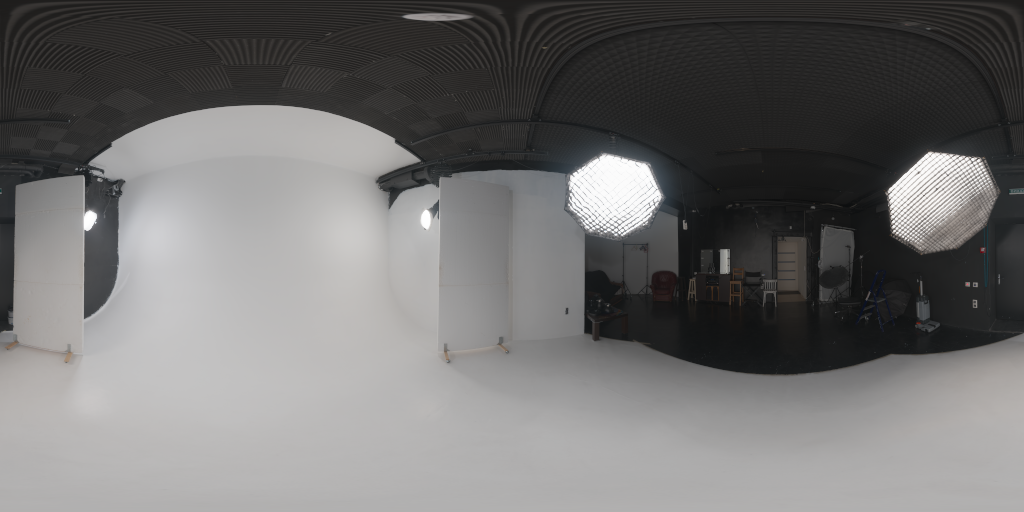

In [5]:
import cv2

ERP_PATH = Path('./dataset/studio_small_09_1k.hdr')
OUTPUT_DIR = Path('./outputs/studio_small_09_cube')
FACE_SIZE = 512
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def tone_map_hdr(rgb):
    """Reinhard tone mapping and approximate gamma encoding, for previews only."""
    rgb = np.maximum(rgb, 0)
    return (rgb / (1 + rgb)) ** (1 / 2.2)


bgr = cv2.imread(str(ERP_PATH), cv2.IMREAD_UNCHANGED)
if bgr is None:
    raise FileNotFoundError(f'Cannot read HDR image: {ERP_PATH}')
pixels = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32)  # No division by 255.
height, width = pixels.shape[:2]
if width != 2 * height:
    raise ValueError(f'Use a complete 2:1 ERP, got {width}x{height}; do not stretch a crop')
if not np.isfinite(pixels).all():
    raise ValueError('HDR contains non-finite values')

erp = torch.from_numpy(pixels).permute(2, 0, 1).unsqueeze(0)  # [1, 3, H, W]
erp = erp.to(DEVICE)
print('Input:', ERP_PATH)
print('ERP shape:', tuple(erp.shape), 'dtype:', erp.dtype)
print('HDR range:', (erp.min().item(), erp.max().item()))

# Tone mapping affects the preview only; erp remains the original floating-point HDR.
erp_preview = Image.fromarray(np.rint(tone_map_hdr(pixels) * 255).astype(np.uint8))
erp_preview.thumbnail((1024, 512))
display(erp_preview)

In [6]:
directions = make_face_directions(FACE_SIZE, '+Z', erp.device, erp.dtype)
grid = make_erp_sampling_grid(directions, height, width)
padded_erp = torch.cat((erp[..., -1:], erp, erp[..., :1]), dim=-1)
front = F.grid_sample(
    padded_erp, grid.unsqueeze(0), mode='bilinear',
    padding_mode='border', align_corners=False,
)
print('directions:', tuple(directions.shape))
print('grid:', tuple(grid.shape), 'range:', (grid.min().item(), grid.max().item()))
print('front:', tuple(front.shape))

cube = erp_to_cubemap(erp, FACE_SIZE)
torch.testing.assert_close(front, cube[:, 4])  # +Z is face index 4.
print('cubemap:', tuple(cube.shape), 'device:', cube.device)

directions: (512, 512, 3)
grid: (512, 512, 2) range: (-0.49937713146209717, 0.49937713146209717)
front: (1, 3, 512, 512)
cubemap: (1, 6, 3, 512, 512) device: cuda:0


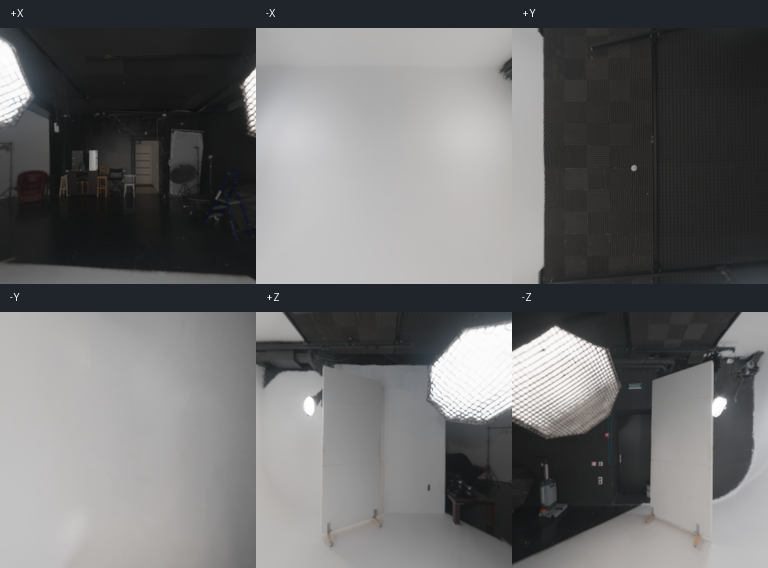

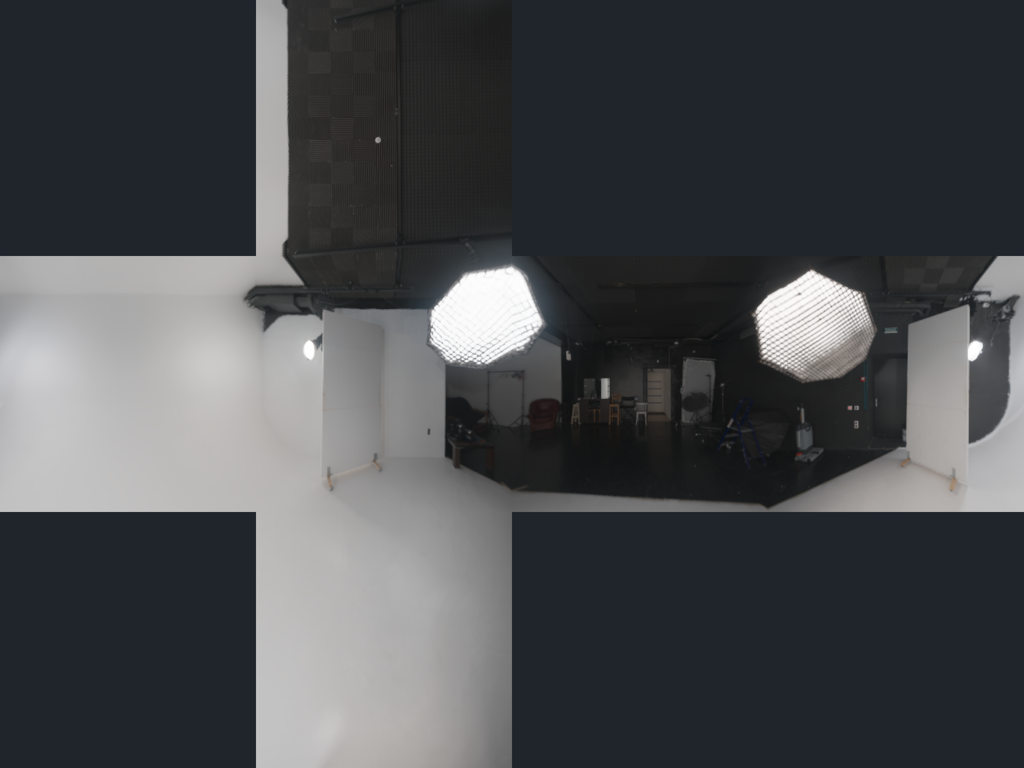

In [7]:
def tensor_to_rgb_image(chw, tone_map=False):
    """Convert RGB [3,H,W] to a PNG preview, optionally tone mapping HDR."""
    array = chw.detach().cpu().permute(1, 2, 0).numpy()
    if tone_map:
        array = tone_map_hdr(array)
    return Image.fromarray(np.rint(np.clip(array, 0, 1) * 255).astype(np.uint8))


def make_face_sheet(cubemap, tile_size=256, tone_map=False):
    """A labeled 2x3 contact sheet; this layout is not a cube net."""
    label_height = 28
    canvas = Image.new('RGB', (3 * tile_size, 2 * (tile_size + label_height)), '#20242b')
    draw = ImageDraw.Draw(canvas)
    for index, name in enumerate(FACE_NAMES):
        left = (index % 3) * tile_size
        top = (index // 3) * (tile_size + label_height)
        tile = tensor_to_rgb_image(cubemap[0, index], tone_map=tone_map).resize(
            (tile_size, tile_size), Image.Resampling.LANCZOS,
        )
        draw.text((left + 10, top + 7), name, fill='white')
        canvas.paste(tile, (left, top + label_height))
    return canvas


def make_cube_cross(cubemap, tone_map=False):
    """Cube net: +Y above +Z; -X,+Z,+X,-Z across; -Y below +Z."""
    size = cubemap.shape[-1]
    canvas = Image.new('RGB', (4 * size, 3 * size), '#20242b')
    placements = {'+Y': (1, 0), '-X': (0, 1), '+Z': (1, 1),
                  '+X': (2, 1), '-Z': (3, 1), '-Y': (1, 2)}
    for index, name in enumerate(FACE_NAMES):
        col, row = placements[name]
        canvas.paste(tensor_to_rgb_image(cubemap[0, index], tone_map=tone_map), (col * size, row * size))
    return canvas


face_sheet = make_face_sheet(cube, tone_map=True)
cube_cross = make_cube_cross(cube, tone_map=True)
display(face_sheet)
cross_preview = cube_cross.copy()
cross_preview.thumbnail((1024, 768))
display(cross_preview)

In [8]:
# Export tone-mapped PNG previews. cube retains the floating-point HDR values.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FILE_NAMES = ('posx', 'negx', 'posy', 'negy', 'posz', 'negz')
for index, name in enumerate(FILE_NAMES):
    tensor_to_rgb_image(cube[0, index], tone_map=True).save(OUTPUT_DIR / f'{name}.png')
erp_preview.save(OUTPUT_DIR / 'erp_preview.png')
face_sheet.save(OUTPUT_DIR / 'cubemap_faces.png')
cube_cross.save(OUTPUT_DIR / 'cubemap_cross.png')
print('Saved six faces and previews to:', OUTPUT_DIR)

Saved six faces and previews to: outputs\studio_small_09_cube
